# ARTI403 – Image Processing

**Name:** Abdulsamad Mousa Yahya Tuhaysha &nbsp;&nbsp; **ID:** 2240001093

---

# **Lab 7(B) - Mathematical and Statistical Filters**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

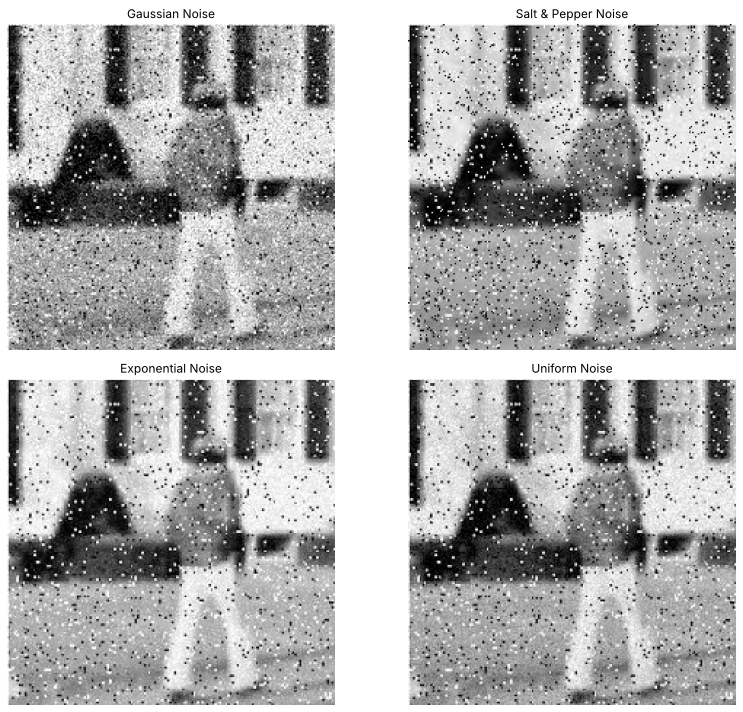

In [2]:
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = 'images/noise.jpg'
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)



# 2. Load image in grayscale
img = cv2.imread(imgPath, 0)

# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()


In [3]:
# --- METHOD 1: Using Built-in OpenCV function ---

# 2. Apply Arithmetic Mean Filter (using a 5x5 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes.,
# you can change kernel size to (5,5), (7,7) etc.
filtered_img = cv2.blur(noise_gauss, (3, 3))

display(filtered_img)

array([[133, 152,  91, ..., 207, 204, 217],
       [131, 146,  90, ..., 216, 210, 210],
       [ 78,  92,  22, ..., 203, 196, 198],
       ...,
       [187, 182, 156, ..., 152, 139, 128],
       [181, 176, 146, ..., 135, 130, 130],
       [172, 172, 148, ..., 133, 121, 120]], shape=(224, 225), dtype=uint8)

In [4]:
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(img, -1, kernel)

display(arithmetic_mean_manual)

array([[135, 136,  81, ..., 205, 209, 206],
       [132, 139,  89, ..., 216, 214, 208],
       [ 82,  92,  23, ..., 195, 195, 189],
       ...,
       [182, 182, 150, ..., 149, 150, 154],
       [175, 175, 142, ..., 141, 139, 139],
       [170, 174, 140, ..., 140, 138, 133]], shape=(224, 225), dtype=uint8)

## **Geometric Means**

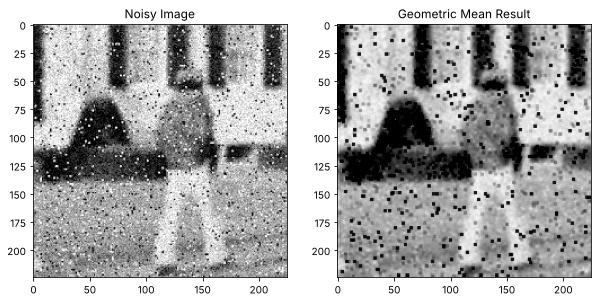

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

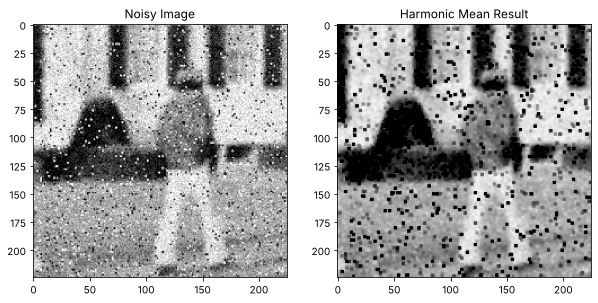

In [6]:

def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img, cmap='gray'), plt.title('Harmonic Mean Result')
plt.show()


## **Contra - Harmonic Mean Filter**

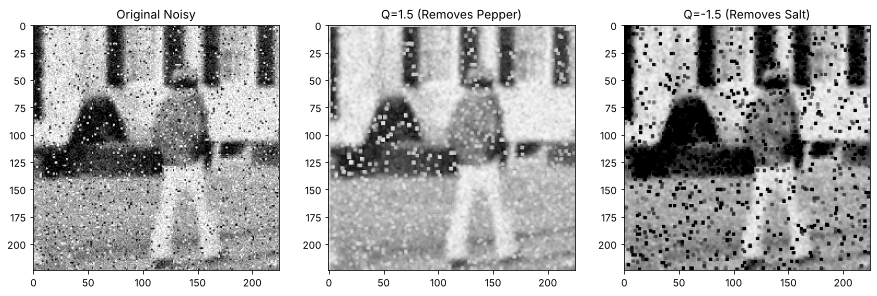

In [7]:


def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed, cmap='gray'), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


## **Median Filter**

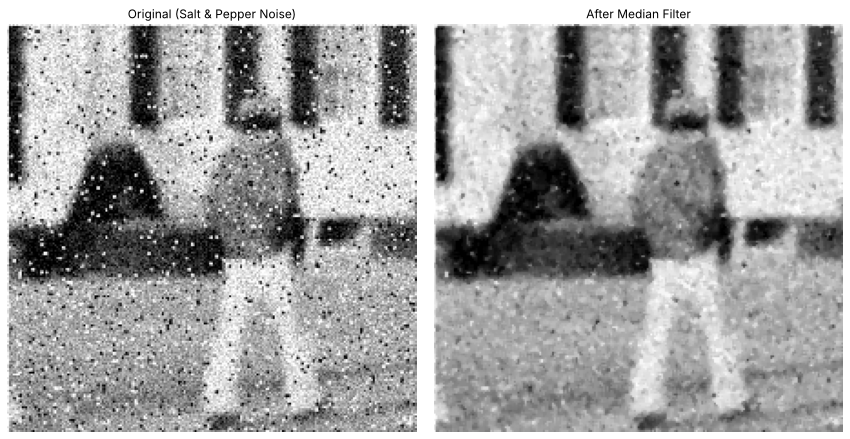

In [8]:



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result, cmap='gray'), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Max and Min Filter**

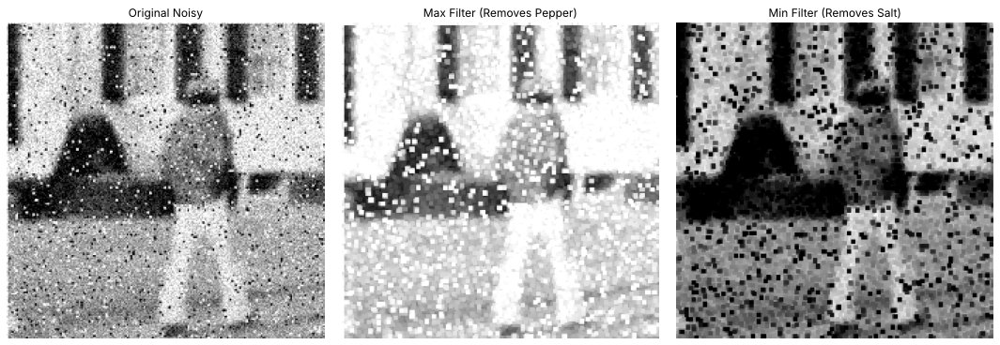

In [9]:


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss



# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter, cmap='gray'), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter, cmap='gray'), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filtering**

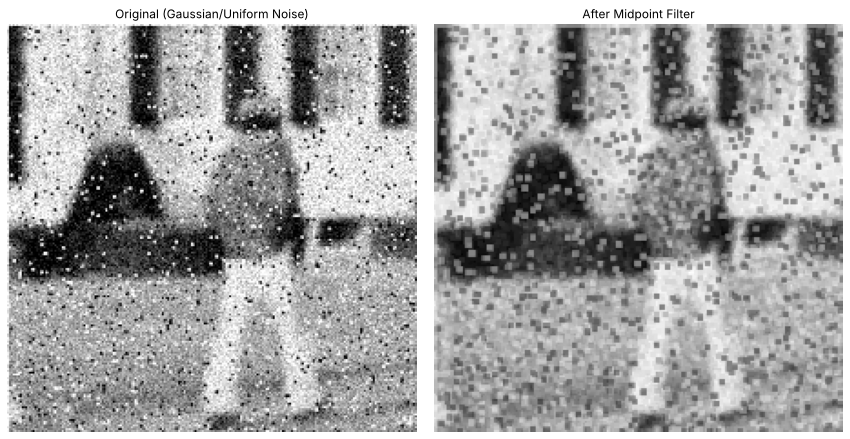

In [10]:

def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Gaussian/Uniform Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()


---
# **RGB Part: Mathematical and Statistical Filters on Colour Images**

The same noise models and filters are applied to an RGB image here.

- **Noise:** Gaussian, exponential and uniform noise get an independent random value for each channel of each pixel. For salt & pepper, the whole pixel (all three channels) is set to white or black, which is what a dead or stuck pixel looks like.
- **Filters:** each filter is applied to the R, G and B channels separately with a helper `apply_rgb()`, then the channels are merged back. (Most OpenCV functions would also accept the 3-channel image directly, the result is the same; this is checked below.)
- **PSNR** against the clean image is printed for every result, so the filters can be compared with numbers.

RGB image shape: (400, 600, 3)


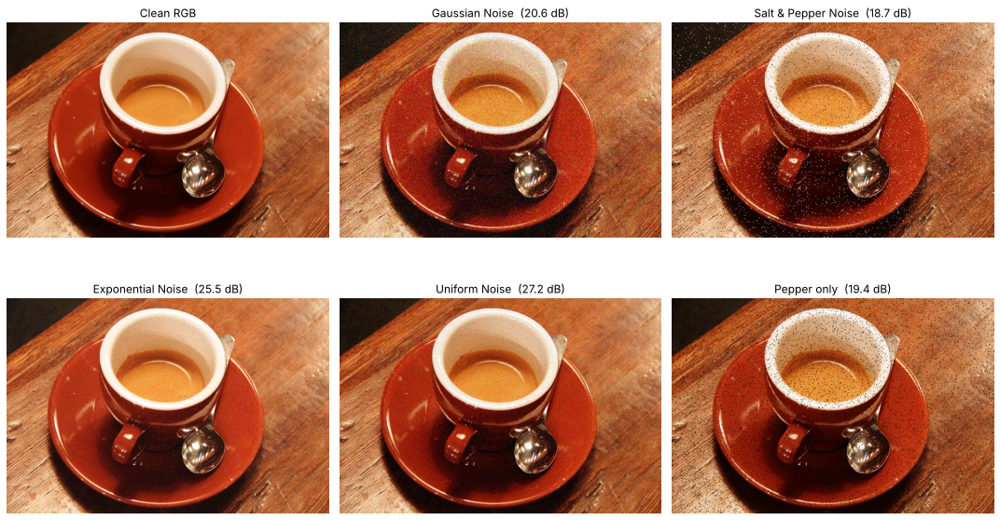

In [11]:
# ========== ( Load RGB image and add noise ) =================
import os

rgbPath = "images/coffee.jpg"      # any colour pic works

if not os.path.exists(rgbPath):
    from skimage import data
    cv2.imwrite(rgbPath, cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR))

rgb = cv2.cvtColor(cv2.imread(rgbPath), cv2.COLOR_BGR2RGB)
print("RGB image shape:", rgb.shape)

np.random.seed(7)   # fixed seed so I get the same noise every run

def add_noise_rgb(image, noise_type, amount=0.04):
    shape = image.shape                    # rows, cols, 3

    if noise_type == "gaussian":
        gauss = np.random.normal(0, 0.01 ** 0.5, shape)
        return np.clip((image / 255 + gauss) * 255, 0, 255).astype(np.uint8)

    if noise_type == "exponential":
        return np.clip(image + np.random.exponential(10.0, shape), 0, 255).astype(np.uint8)

    if noise_type == "uniform":
        return np.clip(image + np.random.uniform(-20, 20, shape), 0, 255).astype(np.uint8)

    # salt/pepper: I set all 3 channels so the dot is pure white or black
    noisy = image.copy()
    rows, cols = shape[:2]
    n = int(amount * rows * cols)
    if noise_type in ("salt_pepper", "salt"):
        k = n // 2 if noise_type == "salt_pepper" else n
        noisy[np.random.randint(0, rows, k), np.random.randint(0, cols, k)] = 255
    if noise_type in ("salt_pepper", "pepper"):
        k = n // 2 if noise_type == "salt_pepper" else n
        noisy[np.random.randint(0, rows, k), np.random.randint(0, cols, k)] = 0
    return noisy

rgb_gauss = add_noise_rgb(rgb, "gaussian")
rgb_sp    = add_noise_rgb(rgb, "salt_pepper")
rgb_expo  = add_noise_rgb(rgb, "exponential")
rgb_uni   = add_noise_rgb(rgb, "uniform")
rgb_pepper = add_noise_rgb(rgb, "pepper", 0.05)
rgb_salt   = add_noise_rgb(rgb, "salt", 0.05)

# PSNR in dB, higher = closer to the clean pic
def psnr(clean, test):
    mse = np.mean((clean.astype(np.float64) - test.astype(np.float64)) ** 2)
    return 99.0 if mse == 0 else 10 * np.log10(255 ** 2 / mse)

plt.figure(figsize=(15, 9))
for i, (im, t) in enumerate([(rgb, 'Clean RGB'), (rgb_gauss, 'Gaussian Noise'), (rgb_sp, 'Salt & Pepper Noise'),
                             (rgb_expo, 'Exponential Noise'), (rgb_uni, 'Uniform Noise'), (rgb_pepper, 'Pepper only')]):
    plt.subplot(2, 3, i + 1), plt.imshow(im), plt.axis('off')
    plt.title(t if i == 0 else f'{t}  ({psnr(rgb, im):.1f} dB)')
plt.tight_layout()
plt.show()


In [12]:
# ========== ( Helper: run a gray filter on each channel ) ==========
# split -> filter each one -> merge back

def apply_rgb(filter_func, image, **kwargs):
    channels = cv2.split(image)                          # split into R, G, B
    filtered = [filter_func(c, **kwargs) for c in channels]
    return cv2.merge(filtered)

# just so I don't repeat the same plotting code 10 times
def show_pair(noisy, result, name):
    plt.figure(figsize=(12, 5))
    plt.subplot(121), plt.imshow(noisy), plt.title(f'Noisy ({psnr(rgb, noisy):.1f} dB)'), plt.axis('off')
    plt.subplot(122), plt.imshow(result), plt.title(f'{name} ({psnr(rgb, result):.1f} dB)'), plt.axis('off')
    plt.tight_layout()
    plt.show()


## **Arithmetic Mean (RGB)**

Max difference between method 1 and method 2: 0


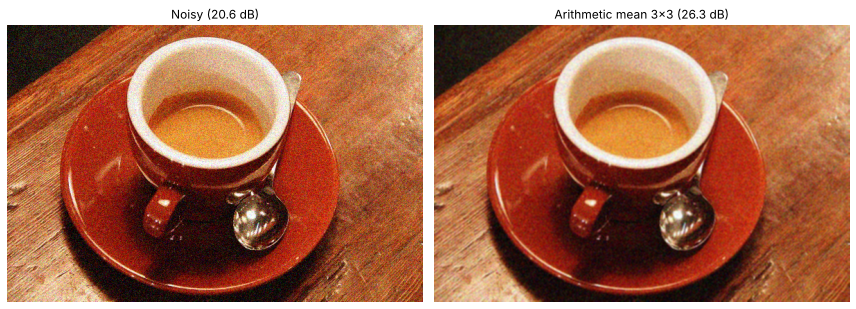

In [13]:
# --- METHOD 1: built in, cv2.blur is fine with colour ---
arith_rgb_1 = cv2.blur(rgb_gauss, (3, 3))

# --- METHOD 2: my own kernel, one channel at a time ---
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arith_rgb_2 = apply_rgb(lambda c: cv2.filter2D(c, -1, kernel), rgb_gauss)

print("Max difference between method 1 and method 2:",
      np.abs(arith_rgb_1.astype(int) - arith_rgb_2.astype(int)).max())

show_pair(rgb_gauss, arith_rgb_2, 'Arithmetic mean 3x3')


## **Geometric Mean (RGB)**

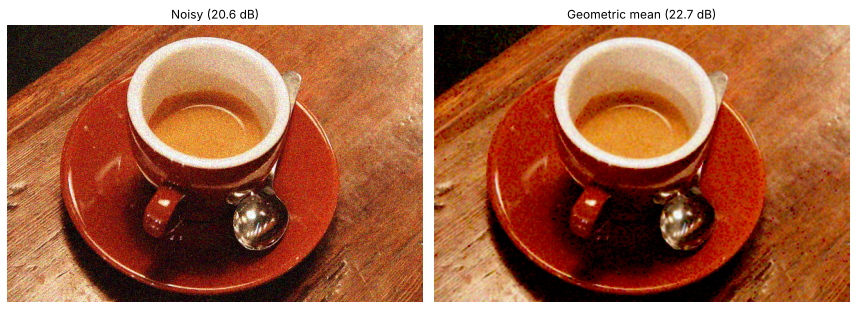

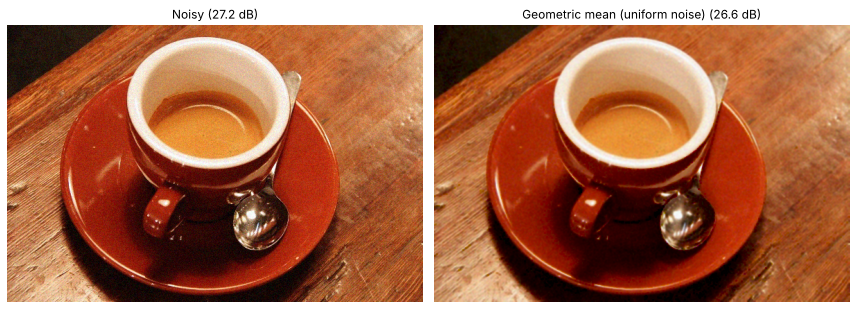

In [14]:
# reusing geometric_mean_filter() from the gray part above, no changes needed
geo_rgb = apply_rgb(geometric_mean_filter, rgb_gauss, kernel_size=3)
show_pair(rgb_gauss, geo_rgb, 'Geometric mean')

geo_rgb_uni = apply_rgb(geometric_mean_filter, rgb_uni, kernel_size=3)
show_pair(rgb_uni, geo_rgb_uni, 'Geometric mean (uniform noise)')


## **Harmonic Mean (RGB)**

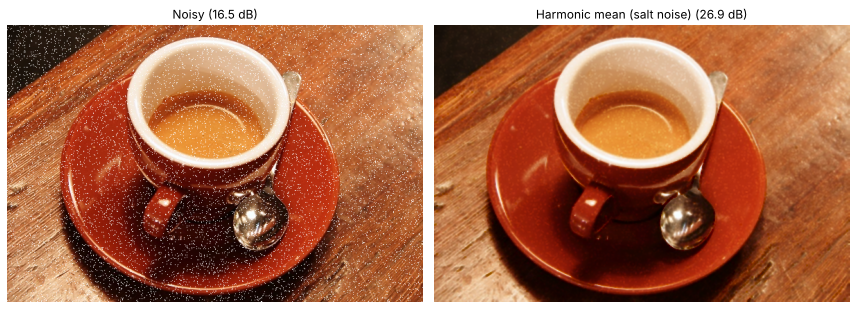

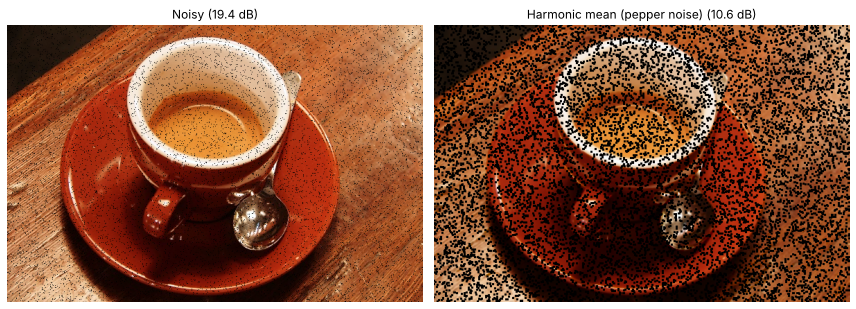

In [15]:
# harmonic should be ok on salt and bad on pepper, testing both
harm_rgb_salt = apply_rgb(harmonic_mean_filter, rgb_salt, kernel_size=3)
show_pair(rgb_salt, harm_rgb_salt, 'Harmonic mean (salt noise)')

harm_rgb_pepper = apply_rgb(harmonic_mean_filter, rgb_pepper, kernel_size=3)
show_pair(rgb_pepper, harm_rgb_pepper, 'Harmonic mean (pepper noise)')


## **Contra-Harmonic Mean (RGB)**

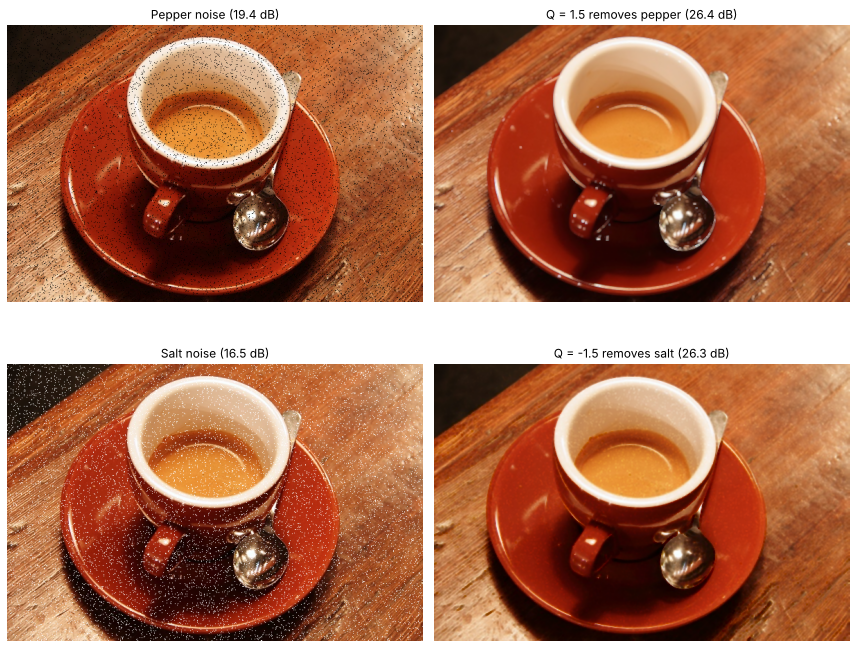

In [16]:
# Q > 0 for pepper, Q < 0 for salt (wrong sign makes it way worse)
pepper_removed_rgb = apply_rgb(contra_harmonic_mean, rgb_pepper, kernel_size=3, Q=1.5)
salt_removed_rgb   = apply_rgb(contra_harmonic_mean, rgb_salt,   kernel_size=3, Q=-1.5)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(rgb_pepper), plt.title(f'Pepper noise ({psnr(rgb, rgb_pepper):.1f} dB)')
plt.subplot(222), plt.imshow(pepper_removed_rgb), plt.title(f'Q = 1.5 removes pepper ({psnr(rgb, pepper_removed_rgb):.1f} dB)')
plt.subplot(223), plt.imshow(rgb_salt), plt.title(f'Salt noise ({psnr(rgb, rgb_salt):.1f} dB)')
plt.subplot(224), plt.imshow(salt_removed_rgb), plt.title(f'Q = -1.5 removes salt ({psnr(rgb, salt_removed_rgb):.1f} dB)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Median Filter (RGB)**

Per-channel vs direct, max difference: 0


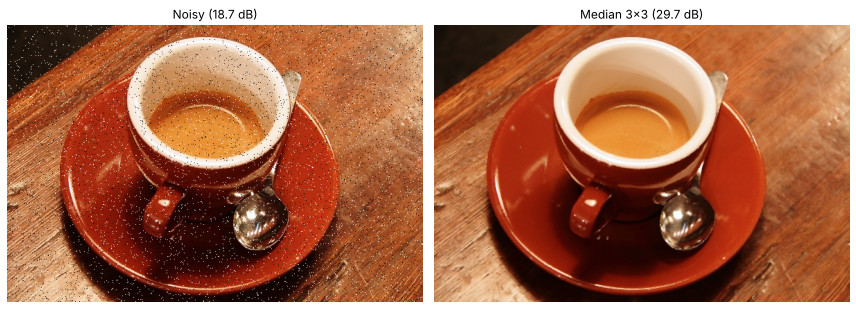

In [17]:
median_rgb = apply_rgb(cv2.medianBlur, rgb_sp, ksize=3)
median_rgb_direct = cv2.medianBlur(rgb_sp, 3)          # should be identical, just checking

print("Per-channel vs direct, max difference:",
      np.abs(median_rgb.astype(int) - median_rgb_direct.astype(int)).max())

show_pair(rgb_sp, median_rgb, 'Median 3x3')


## **Max and Min Filter (RGB)**

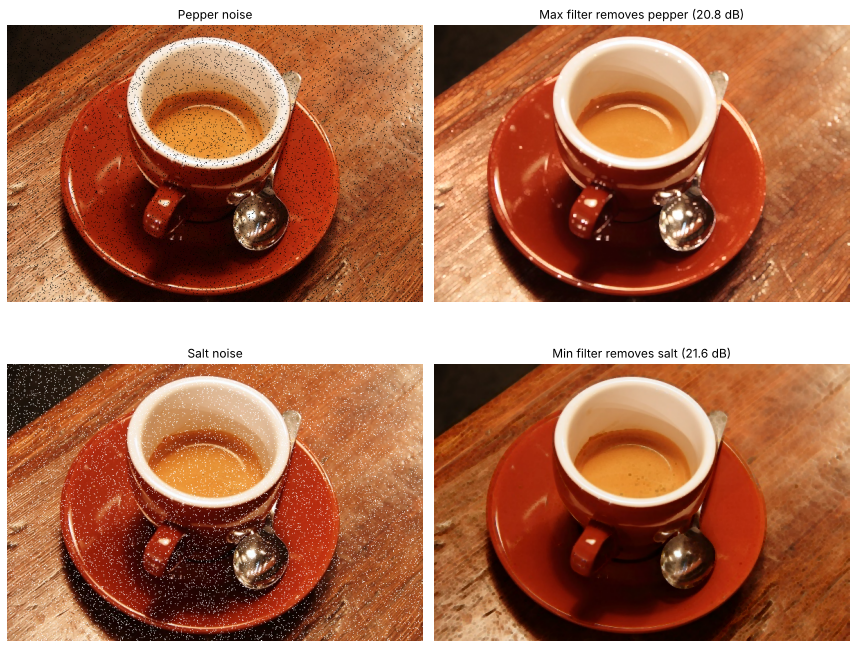

In [18]:
kernel = np.ones((3, 3), np.uint8)

max_rgb = apply_rgb(cv2.dilate, rgb_pepper, kernel=kernel)   # max -> kills the black dots
min_rgb = apply_rgb(cv2.erode,  rgb_salt,   kernel=kernel)   # min -> kills the white dots

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(rgb_pepper), plt.title('Pepper noise')
plt.subplot(222), plt.imshow(max_rgb), plt.title(f'Max filter removes pepper ({psnr(rgb, max_rgb):.1f} dB)')
plt.subplot(223), plt.imshow(rgb_salt), plt.title('Salt noise')
plt.subplot(224), plt.imshow(min_rgb), plt.title(f'Min filter removes salt ({psnr(rgb, min_rgb):.1f} dB)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filter (RGB)**

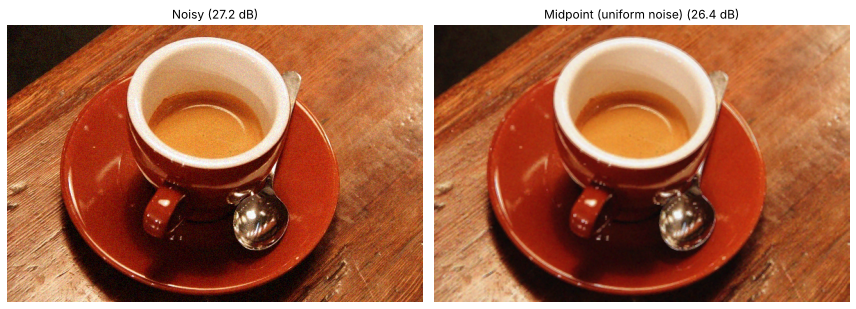

In [19]:
# midpoint = (max + min) / 2, works best when noise is bounded like uniform
mid_rgb = apply_rgb(midpoint_filter, rgb_uni, kernel_size=3)
show_pair(rgb_uni, mid_rgb, 'Midpoint (uniform noise)')


## **Comparison of all filters on RGB (PSNR in dB)**

In [20]:
# run everything on everything and print a table, easier to compare than pics
filters_rgb = {
    "Arith":        lambda c: cv2.blur(c, (3, 3)),
    "Geo":          lambda c: geometric_mean_filter(c, 3),
    "Harm":         lambda c: harmonic_mean_filter(c, 3),
    "CH Q=1.5":     lambda c: contra_harmonic_mean(c, 3, Q=1.5),
    "CH Q=-1.5":    lambda c: contra_harmonic_mean(c, 3, Q=-1.5),
    "Median":       lambda c: cv2.medianBlur(c, 3),
    "Max":          lambda c: cv2.dilate(c, np.ones((3, 3), np.uint8)),
    "Min":          lambda c: cv2.erode(c, np.ones((3, 3), np.uint8)),
    "Midpoint":     lambda c: midpoint_filter(c, 3),
}
noisy_rgb = {"Gaussian": rgb_gauss, "Uniform": rgb_uni, "Exponential": rgb_expo,
             "Salt&Pepper": rgb_sp, "Pepper": rgb_pepper, "Salt": rgb_salt}

header = f"{'Noise':<12}{'Noisy':>7}" + "".join(f"{k:>10}" for k in filters_rgb)
print(header)
print("-" * len(header))
best_list = []
for nname, nimg in noisy_rgb.items():
    scores = {k: psnr(rgb, apply_rgb(f, nimg)) for k, f in filters_rgb.items()}
    best = max(scores, key=scores.get)
    row = f"{nname:<12}{psnr(rgb, nimg):>7.1f}" + "".join(f"{v:>10.1f}" for v in scores.values())
    print(row)
    best_list.append((nname, best))
print()
for nname, best in best_list:
    print(f"Best for {nname:<12}: {best}")


Noise         Noisy     Arith       Geo      Harm  CH Q=1.5 CH Q=-1.5    Median       Max       Min  Midpoint
-------------------------------------------------------------------------------------------------------------
Gaussian       20.6      26.3      22.7      21.3      21.2      20.5      25.6      15.0      15.7      23.8
Uniform        27.2      28.3      26.6      25.5      25.2      24.6      28.1      19.0      19.4      26.4
Exponential    25.5      25.6      26.4      26.3      22.7      26.0      26.8      16.4      22.7      23.0
Salt&Pepper    18.7      25.3      14.9      14.0      13.8      13.9      29.7      10.9      13.5      16.0
Pepper         19.4      25.1      11.5      10.6      26.4      10.6      29.4      20.8      10.5      17.0
Salt           16.5      23.2      26.9      26.9      10.2      26.3      29.6       7.6      21.6      14.0

Best for Gaussian    : Arith
Best for Uniform     : Arith
Best for Exponential : Median
Best for Salt&Pepper : Median
B

## Observations (RGB)

- Every filter from the grayscale part works on RGB by filtering R, G and B separately. `cv2.blur`, `cv2.medianBlur`, `cv2.dilate` and `cv2.erode` already do this when given a 3-channel image. The checks above print a difference of 0 between the per-channel helper and the direct call.
- **Gaussian and uniform noise:** the arithmetic mean gave the best PSNR (20.6 to 26.3 dB and 27.2 to 28.3 dB), with the median close behind. The gain on uniform noise is small because the coffee photo has a lot of fine texture, and a 3x3 average removes some real detail along with the noise.
- **Salt & pepper:** the median is far ahead (18.7 to 29.7 dB). The geometric, harmonic and contraharmonic filters all make it worse, because each of them is pulled toward one extreme.
- **One-sided impulse noise:** with the right sign, the contraharmonic filter works (pepper 19.4 to 26.4 dB with Q = 1.5, salt 16.5 to 26.3 dB with Q = -1.5). With the wrong sign it drops to about 10 dB. Harmonic and geometric clean salt (26.9 dB) but fail on pepper. Max removes pepper and min removes salt, but both thicken bright or dark details, so they score lower (20.8 and 21.6 dB).
- **Exponential noise:** on this photo the median was best (26.8 dB). The min filter, which works on flat images because exponential noise only adds brightness, scored only 22.7 dB here because it also erases thin bright details such as the reflections on the cup.
- Gaussian, exponential and uniform noise were added to each channel independently, so the noise looks like coloured speckle. Filtering each channel separately leaves a little colour noise behind, and at strong edges it can create small colour shifts, because the median of R and the median of G may come from different neighbours. A vector median, or filtering only the luminance channel, avoids this.